# Where the self-distillation signal is

Hinted teacher vs unhinted student (same Qwen3.5-9B, bf16) on `runs/distill/all_after_hint_scored.jsonl`: 218 trajectories that didn't submit by turn 40, a hint before a turn in 30–39, and every supervised token from that turn to the end. For each supervised token the file holds the teacher's top-20 tokens with their log-probs, and the student's log-probs of the same 20 tokens.

Each section is one note, followed by the evidence for it. Every number is computed in the section that uses it; slow steps (reading the 7.3 GB file) save their result to a cache under `runs/distill/`, so reruns are fast. Delete a cache to recompute it.

## Setup

Imports, plot style, file paths, and two display helpers. No numbers here.

In [1]:
import html
import json
import os
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML, display
from transformers import AutoTokenizer

REPO = Path.cwd() if (Path.cwd() / "sd").exists() else Path.cwd().parent
os.chdir(REPO)
SCORED = Path("runs/distill/all_after_hint_scored.jsonl")  # examples + teacher top-20 and student scores
EXAMPLES = Path("runs/distill/all_after_hint.jsonl")       # same examples, same order, without the scores

tok = AutoTokenizer.from_pretrained("Qwen/Qwen3.5-9B")

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK_2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": MUTED,
    "axes.labelcolor": INK_2, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False,
    "axes.spines.right": False, "axes.titlelocation": "left", "axes.titlesize": 12, "font.size": 10,
})


def show_table(headers, rows, align=None):
    align = align or "l" + "r" * (len(headers) - 1)
    cell = lambda a: f'text-align:{"left" if a == "l" else "right"}; padding:4px 12px'
    th = "".join(f'<th style="{cell(a)}; color:{INK_2}; border-bottom:1px solid {MUTED}">{h}</th>' for h, a in zip(headers, align))
    body = "".join("<tr>" + "".join(f'<td style="{cell(a)}; border-bottom:1px solid {GRID}; font-variant-numeric:tabular-nums">{v}</td>'
                                    for v, a in zip(row, align)) + "</tr>" for row in rows)
    display(HTML(f'<table style="font:13px system-ui; border-collapse:collapse; color:{INK}; background:#fcfcfb">'
                 f'<tr>{th}</tr>{body}</table>'))


def visible(s):
    return html.escape(s).replace("\n", f'<span style="color:{MUTED}">↵</span>')

/Users/dmorara/repos/applied-compute/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## The training signal per token

The training loss is the top-20 KL: the teacher renormalized over its top 20 ($p_T$) against the student's probabilities of the same tokens ($p_S$). Renormalizing adds $-\log(\text{teacher's top-20 mass})$ at every token, hint or not. That term doesn't depend on the student, so it has no gradient. The **training signal** is the KL without it, which is 0 when teacher and student agree:

$$\text{signal} = \sum_{k \in \text{top-20}} p_T(k)\,\big(\log q_T(k) - \log p_S(k)\big)$$

with $q_T$ the teacher's raw (not renormalized) probabilities.

Per supervised token this keeps: its example, its turn since the hint (0 = the hint turn; turns are the runs of 1s in `target_mask`), its index among the supervised tokens since the hint, and its signal.

In [2]:
TOKEN_SIGNAL = Path("runs/distill/token_signal.npz")


def build_token_signal():
    rows = []
    with SCORED.open() as f:
        for i, line in enumerate(f):
            e = json.loads(line)
            m = np.array(e["target_mask"], bool)
            log_q_t = np.array(e["teacher_topk_logprobs"], np.float64)[m]  # teacher, raw
            log_p_s = np.array(e["student_topk_logprobs"], np.float64)[m]  # student, same 20 tokens
            p_t = np.exp(log_q_t - np.logaddexp.reduce(log_q_t, axis=1, keepdims=True))  # teacher renormalized
            rows.append({"example": np.full(m.sum(), i),
                         "turn": np.cumsum(m & ~np.r_[False, m[:-1]])[m] - 1,
                         "token": np.arange(m.sum()),
                         "signal": (p_t * (log_q_t - log_p_s)).sum(1)})
    np.savez(TOKEN_SIGNAL, **{k: np.concatenate([r[k] for r in rows]) for k in rows[0]})


if not TOKEN_SIGNAL.exists():
    build_token_signal()
data = dict(np.load(TOKEN_SIGNAL))
example, turn, token, signal = data["example"], data["turn"], data["token"], data["signal"]
n_examples = example.max() + 1
offsets = np.r_[0, np.cumsum(np.bincount(example))]  # example i's tokens are offsets[i]:offsets[i + 1]
print(f"{n_examples} examples, {len(signal):,} supervised tokens")

218 examples, 4,083,747 supervised tokens


## 1. The training signal diminishes with time

* It drops about 100× by turn 20

Signal per token by distance from the hint, measured two ways: assistant turns since the hint, and supervised tokens since the hint. A curve point is the mean over examples of each example's mean signal at that distance, so every example counts equally; the band is a 95% bootstrap over examples.

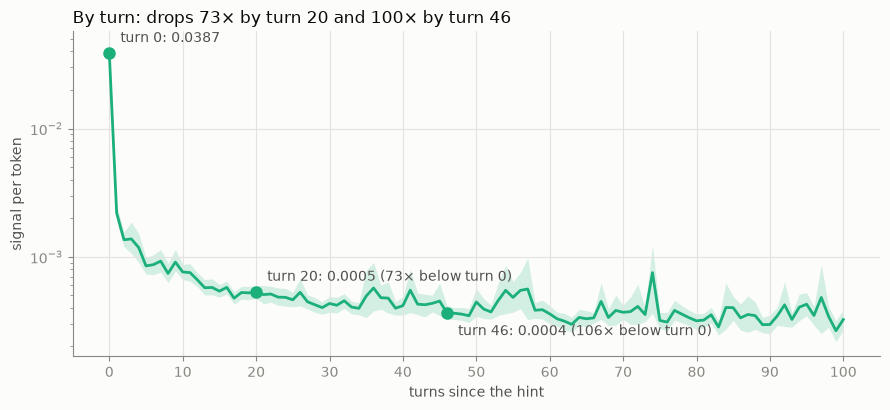

In [3]:
def per_example(values, bins, n_bins):
    """(examples, bins): each example's mean value per bin, NaN where it has no tokens."""
    keep = (bins >= 0) & (bins < n_bins)
    sums = np.zeros((n_examples, n_bins)); counts = np.zeros((n_examples, n_bins))
    np.add.at(sums, (example[keep], bins[keep]), values[keep])
    np.add.at(counts, (example[keep], bins[keep]), 1)
    return np.where(counts > 0, sums / np.maximum(counts, 1), np.nan)


def mean_and_band(per_ex, n_boot=500, seed=0):
    """Mean over examples and a 95% bootstrap band (resampling examples)."""
    rng = np.random.default_rng(seed)
    boot = np.array([np.nanmean(per_ex[rng.integers(0, n_examples, n_examples)], 0) for _ in range(n_boot)])
    return np.nanmean(per_ex, 0), *np.nanpercentile(boot, [2.5, 97.5], axis=0)


MAX_TURN = 100
by_turn = per_example(signal, turn, MAX_TURN + 1)
mean, lo, hi = mean_and_band(by_turn)
x = np.arange(MAX_TURN + 1)
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.fill_between(x, lo, hi, color=AQUA, alpha=0.18, linewidth=0)
ax.plot(x, mean, color=AQUA, linewidth=2)
ax.set_yscale("log")
ax.set_xticks(np.arange(0, MAX_TURN + 1, 10))
turn_100x = int(np.argmax(mean <= mean[0] / 100))  # first turn 100x below the hint turn
for t in (0, 20, turn_100x):
    ax.plot(t, mean[t], "o", color=AQUA, markersize=8)
    label = f"turn {t}: {mean[t]:.4f}" + (f" ({mean[0] / mean[t]:.0f}× below turn 0)" if t else "")
    ax.annotate(label, (t, mean[t]), xytext=(8, 8 if t != turn_100x else -16), textcoords="offset points", color=INK_2)
ax.set_xlabel("turns since the hint")
ax.set_ylabel("signal per token")
ax.set_title(f"By turn: drops {mean[0] / mean[20]:.0f}× by turn 20 and 100× by turn {turn_100x}")
fig.tight_layout()

The same by supervised tokens since the hint (log-spaced bins, both axes log). The dashed line is the median length of the hint turn.

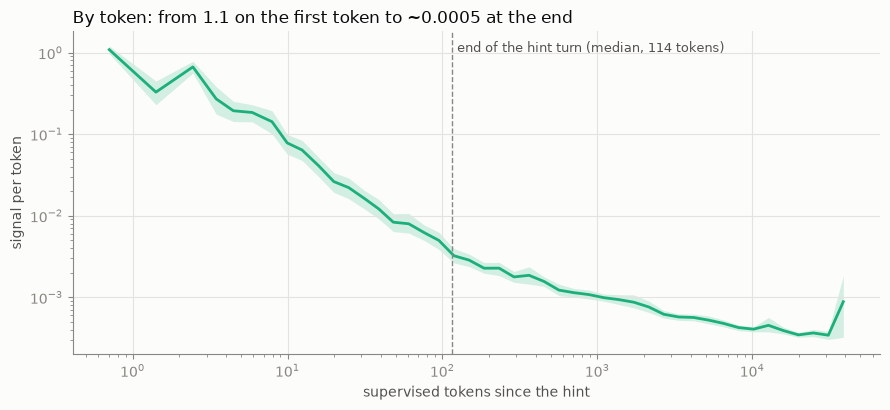

In [4]:
edges = np.unique(np.r_[0, np.geomspace(1, token.max() + 1, 50).astype(int)])
token_bin = np.searchsorted(edges, token, side="right") - 1
by_token = per_example(signal, token_bin, len(edges) - 1)
t_mean, t_lo, t_hi = mean_and_band(by_token)
centers = np.sqrt(np.maximum(edges[:-1], 0.5) * edges[1:])  # geometric middle of each bin
keep = (~np.isnan(by_token)).sum(0) >= 20  # bins reached by at least 20 examples
hint_turn_length = np.median(np.bincount(example[turn == 0]))

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.fill_between(centers[keep], np.clip(t_lo[keep], 1e-6, None), t_hi[keep], color=AQUA, alpha=0.18, linewidth=0)
ax.plot(centers[keep], np.clip(t_mean[keep], 1e-6, None), color=AQUA, linewidth=2)
ax.set_xscale("log"); ax.set_yscale("log")
ax.axvline(hint_turn_length, color=MUTED, linewidth=1, linestyle="--")
ax.annotate(f"end of the hint turn (median, {hint_turn_length:.0f} tokens)", (hint_turn_length, 0.97),
            xycoords=("data", "axes fraction"), xytext=(4, 0), textcoords="offset points", color=INK_2, va="top", fontsize=9)
ax.set_xlabel("supervised tokens since the hint")
ax.set_ylabel("signal per token")
ax.set_title(f"By token: from {t_mean[0]:.1f} on the first token to ~{np.nanmean(t_mean[keep][-5:]):.4f} at the end")
fig.tight_layout()

## 2. It's really big in the first turn

* only the first turn makes up for 37% of the training signal of one example on average
* only the first token makes up for 8% of the training signal and is likely not useful for the behavior

Per example: the share of its total signal in each part of the trajectory, then averaged over examples.

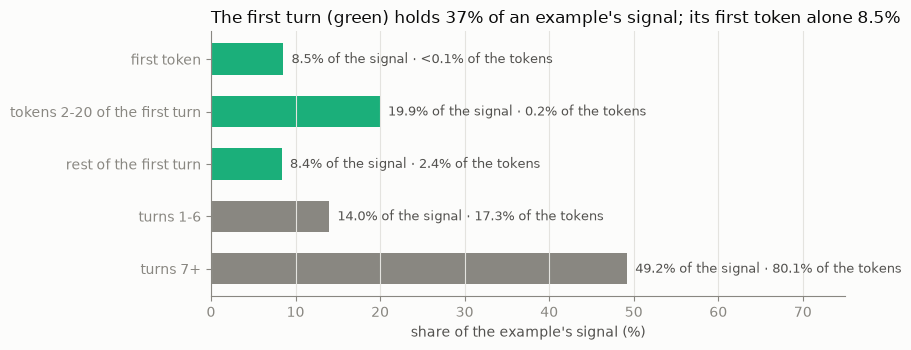

In [5]:
parts = {
    "first token": (turn == 0) & (token == 0),
    "tokens 2-20 of the first turn": (turn == 0) & (token >= 1) & (token < 20),
    "rest of the first turn": (turn == 0) & (token >= 20),
    "turns 1-6": (turn >= 1) & (turn <= 6),
    "turns 7+": turn >= 7,
}
example_total = np.bincount(example, signal, n_examples)
shares = {n: np.mean(np.bincount(example, signal * s, n_examples) / example_total) for n, s in parts.items()}
token_shares = {n: np.mean(np.bincount(example, s.astype(float), n_examples) / np.bincount(example)) for n, s in parts.items()}

fig, ax = plt.subplots(figsize=(9, 3.6))
names = list(parts)[::-1]
first_turn_parts = ("first token", "tokens 2-20 of the first turn", "rest of the first turn")
ax.barh(names, [shares[n] * 100 for n in names], color=[AQUA if n in first_turn_parts else MUTED for n in names], height=0.6)
for k, n in enumerate(names):
    tokens_label = f"{token_shares[n]:.1%}" if token_shares[n] >= 0.001 else "<0.1%"
    ax.annotate(f"{shares[n]:.1%} of the signal · {tokens_label} of the tokens", (shares[n] * 100, k),
                xytext=(6, 0), textcoords="offset points", va="center", color=INK_2, fontsize=9)
first_turn = sum(shares[n] for n in first_turn_parts)
ax.set_xlim(0, 75)
ax.set_xlabel("share of the example's signal (%)")
ax.set_title(f"The first turn (green) holds {first_turn:.0%} of an example's signal; its first token alone {shares['first token']:.1%}")
ax.grid(axis="y", visible=False)
fig.tight_layout()

**What the first token is**: the first word of the reply right after the hint. For each example, read the teacher's top 20 at that token with both models' probabilities, then average over the examples (a word outside the teacher's top 20 counts as 0).

In [6]:
FIRST_TOKEN = Path("runs/distill/first_token.npz")


def build_first_token():
    ids, teacher, student = [], [], []
    with SCORED.open() as f:
        for line in f:
            e = json.loads(line)
            p = int(np.flatnonzero(e["target_mask"])[0])  # first supervised token = first token of the hint turn
            ids.append(e["teacher_topk_ids"][p])
            teacher.append(np.exp(e["teacher_topk_logprobs"][p]))
            student.append(np.exp(e["student_topk_logprobs"][p]))
    np.savez(FIRST_TOKEN, ids=np.array(ids), teacher=np.array(teacher), student=np.array(student))


if not FIRST_TOKEN.exists():
    build_first_token()
first = dict(np.load(FIRST_TOKEN))
rows = []
for w in ["Let", "Now", "The", "I", "Given", "Good"]:
    is_w = first["ids"] == tok.convert_tokens_to_ids(w)
    rows.append([w, f"{np.where(is_w, first['teacher'], 0).sum(1).mean():.1%}",
                 f"{np.where(is_w, first['student'], 0).sum(1).mean():.1%}"])
show_table(["first word", "teacher", "student"], rows)

first word,teacher,student
Let,46.7%,37.0%
Now,6.8%,14.5%
The,8.5%,10.9%
I,23.5%,9.8%
Given,0.3%,0.0%
Good,3.2%,3.0%


The teacher moves probability toward *I* and away from *Now*. That's how the reply starts, not what it decides: the scores only cover the student's own continuation, so there's no evidence the teacher's different opening leads anywhere different.

## 3. When does the training signal slope stabilize?

* it seems that after turn 7 the slope of the training signal is less dominated by time

The slope of the by-turn curve in section 1: at each turn, the % change of the signal per token per turn, from a line fit to log(signal) over the 7 turns around it. The band is a bootstrap over examples. Starts at turn 1: from the hint turn to turn 1 the signal drops ~95%.

/Users/dmorara/repos/applied-compute/.venv/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


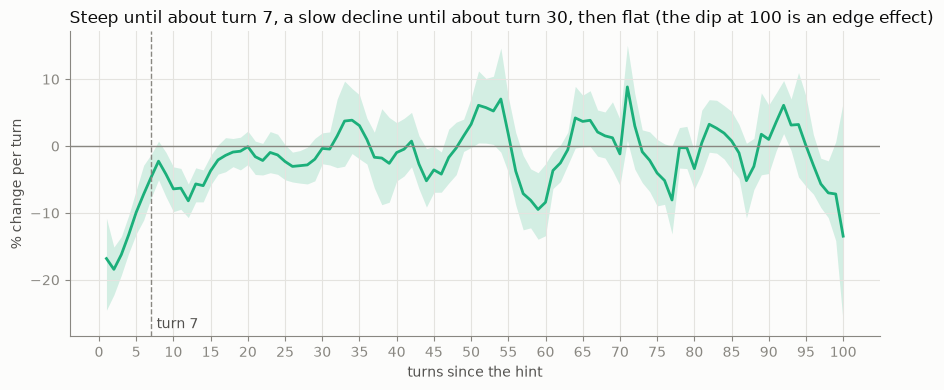

In [7]:
def local_slope(curve, half=3):
    out = np.full(len(curve), np.nan)
    for t in range(1, len(curve)):
        xs = np.arange(max(1, t - half), min(len(curve), t + half + 1))
        if np.isfinite(np.log(curve[xs])).all() and len(xs) >= 3:
            out[t] = np.expm1(np.polyfit(xs, np.log(curve[xs]), 1)[0]) * 100
    return out


slope = local_slope(np.nanmean(by_turn, 0))
rng = np.random.default_rng(0)
boot = np.array([local_slope(np.nanmean(by_turn[rng.integers(0, n_examples, n_examples)], 0)) for _ in range(300)])
lo, hi = np.nanpercentile(boot, [2.5, 97.5], axis=0)
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(1, MAX_TURN + 1)
ax.fill_between(x, lo[1:], hi[1:], color=AQUA, alpha=0.18, linewidth=0)
ax.plot(x, slope[1:], color=AQUA, linewidth=2)
ax.axhline(0, color=MUTED, linewidth=1)
ax.axvline(7, color=MUTED, linewidth=1, linestyle="--")
ax.annotate("turn 7", (7, ax.get_ylim()[0]), xytext=(4, 6), textcoords="offset points", color=INK_2)
ax.set_xticks(np.arange(0, MAX_TURN + 1, 5))
ax.set_xlabel("turns since the hint")
ax.set_ylabel("% change per turn")
ax.set_title("Steep until about turn 7, a slow decline until about turn 30, then flat (the dip at 100 is an edge effect)")
fig.tight_layout()

## 4. After turn 7, is the signal less tied to time?

* yes (mostly)

Rank every supervised token from turn 7 on by its signal. Where in the trajectory do the high-signal tokens sit, compared with all tokens? If the signal were still tied to distance, the top bands would sit earlier.

In [8]:
late = turn >= 7
pct = dict(zip([0, 25, 50, 75, 90, 99, 100], np.quantile(signal[late], [0, .25, .5, .75, .9, .99, 1])))
ranges = [(7, 15), (16, 30), (31, 50), (51, 80), (81, 200)]
groups = {"all tokens, turns 7+": late,
          "p75–p90": late & (signal >= pct[75]) & (signal < pct[90]),
          "p90–p99": late & (signal >= pct[90]) & (signal < pct[99]),
          "top 1%": late & (signal >= pct[99])}
show_table(["tokens"] + [f"turns {a}–{b}" if b < 200 else f"turns {a}+" for a, b in ranges] + ["median turn"],
           [[name] + [f"{(s & (turn >= a) & (turn <= b)).sum() / s.sum():.0%}" for a, b in ranges] + [f"{np.median(turn[s]):.0f}"]
            for name, s in groups.items()])

tokens,turns 7–15,turns 16–30,turns 31–50,turns 51–80,turns 81+,median turn
"all tokens, turns 7+",15%,23%,24%,23%,15%,40
p75–p90,16%,22%,23%,23%,15%,40
p90–p99,19%,24%,23%,21%,13%,36
top 1%,28%,27%,21%,16%,9%,27


p75–p99 are spread across turns like all tokens. Only the top 1% still leans early (median turn 27 vs 40).

## 5. After turn 7, teacher–student disagreement by percentile

* p0–p75: no disagreement. Teacher and student agree to the decimal, so these tokens carry no signal.
* p75–p99: small shifts (1–5 points) on ordinary choices: bash commands, variable names, phrasing. No visible direction when reading samples.
* top 1% (36k tokens): bigger shifts (5–8 points), but still mostly ordinary thinking and code. About 11% of its signal is on finishing or exploring words.

Share of the turns-7+ signal in each percentile band (percentiles of the signal over turns-7+ tokens, from section 4):

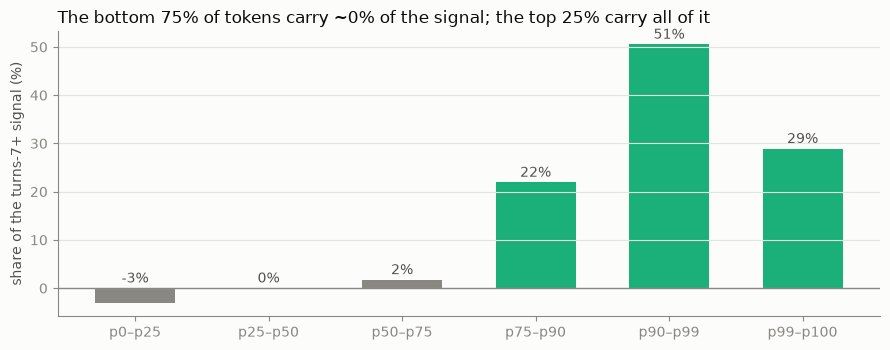

In [9]:
bands = [(0, 25), (25, 50), (50, 75), (75, 90), (90, 99), (99, 100)]
v = signal[late]
band_share = [v[(v >= pct[a]) & ((v <= pct[b]) if b == 100 else (v < pct[b]))].sum() / v.sum() for a, b in bands]
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar([f"p{a}–p{b}" for a, b in bands], np.array(band_share) * 100, color=[MUTED] * 3 + [AQUA] * 3, width=0.6)
for k, sh in enumerate(band_share):
    ax.annotate(f"{sh:.0%}", (k, max(sh, 0) * 100), xytext=(0, 4), textcoords="offset points", ha="center", color=INK_2)
ax.axhline(0, color=MUTED, linewidth=1)
ax.set_ylabel("share of the turns-7+ signal (%)")
ax.set_title("The bottom 75% of tokens carry ~0% of the signal; the top 25% carry all of it")
ax.grid(axis="x", visible=False)
fig.tight_layout()

**Samples.** Random tokens from a band, each with ~300 characters of context. The written token is highlighted; on the right, the teacher's top 3 (renormalized over its 20) with the teacher's probability in blue and the student's in orange.

In [10]:
def band_sample(a, b, n, seed=0):
    in_band = np.flatnonzero(late & (signal >= pct[a]) & (signal < pct[b]))
    return np.random.default_rng(seed).choice(in_band, n, replace=False)


def show_tokens(indices, context=300):
    wanted = {}
    for i in indices:
        wanted.setdefault(int(example[i]), []).append(int(i))
    rows = []
    with SCORED.open() as f:
        for line_no, line in enumerate(f):
            if line_no not in wanted:
                continue
            e = json.loads(line)
            supervised = np.flatnonzero(e["target_mask"])
            for i in wanted[line_no]:
                p = int(supervised[token[i]])  # the token's position in the target
                ids, log_q_t = e["teacher_topk_ids"][p], np.array(e["teacher_topk_logprobs"][p])
                p_t = np.exp(log_q_t - np.logaddexp.reduce(log_q_t))
                p_s = np.exp(e["student_topk_logprobs"][p])
                top3 = "".join(
                    f'<div style="font-size:12px; white-space:nowrap"><code style="background:'
                    f'{"#fde7a6" if ids[k] == e["target"][p] else "transparent"}">{visible(tok.decode([ids[k]]))}</code> '
                    f'<span style="color:{BLUE}">{p_t[k]:.2f}</span> / <span style="color:{ORANGE}">{p_s[k]:.2f}</span></div>'
                    for k in range(3))
                rows.append((signal[i], e["instance_id"], int(turn[i]), tok.decode(e["target"][max(0, p - context):p])[-context:],
                             tok.decode([e["target"][p]]), top3))
    td = f'style="padding:6px 10px; border-bottom:1px solid {GRID}; vertical-align:top"'
    out = "".join(
        f'<tr><td {td}><b>{s:.1e}</b><div style="font-size:11px; color:{INK_2}">{html.escape(iid)}<br>turn +{t}</div></td>'
        f'<td {td}><code style="font-size:12px; white-space:pre-wrap; word-break:break-word">…{visible(ctx)}'
        f'<span style="background:#fde7a6">{visible(w)}</span></code></td><td {td}>{top3}</td></tr>'
        for s, iid, t, ctx, w, top3 in sorted(rows, key=lambda r: -r[0]))
    head = "".join(f'<th style="text-align:left; padding:6px 10px; color:{INK_2}; border-bottom:1px solid {MUTED}">{h}</th>'
                   for h in ["signal", "context → written token (highlighted)",
                             f'top 3: <span style="color:{BLUE}">teacher</span> / <span style="color:{ORANGE}">student</span>'])
    display(HTML(f'<table style="font:13px system-ui; border-collapse:collapse; color:{INK}; background:#fcfcfb; '
                 f'max-width:1100px"><tr>{head}</tr>{out}</table>'))


print("p0–p75, 10 random tokens:")
show_tokens(band_sample(0, 75, 10), context=200)

p0–p75, 10 random tokens:


signal,context → written token (highlighted),top 3: teacher / student
5.7e-07django__django-13925turn +26,…conf import settings↵↵# Remove all created app configurations before running the test↵from django.apps import apps↵parent_apps = list(apps.app_configs.keys())↵↵if not settings.configured:↵ settings.configure,.configure 1.00 / 1.00 = 0.00 / 0.00._ 0.00 / 0.00
4.0e-07sympy__sympy-23413turn +62,"… # See if we're in the right place ↵ output.append(line)↵ i += 1↵↵# Since my check logic was too complex, let me just write the full fixed function instead↵fixed_code = ''' if not A.domain.is",.is 1.00 / 1.00. 0.00 / 0.00 is 0.00 / 0.00
2.9e-08sympy__sympy-20438turn +15,"… real problem from the PR description seems to be:↵1. `b.is_subset(c)` returns `None` (should return `True`)↵2. `c.is_subset(b)` returns `True` - this is correct but inconsistent↵3. `Eq(b, c).simplify()`",()` 1.00 / 1.00() 0.00 / 0.00` 0.00 / 0.00
1.6e-08django__django-11532turn +47,…1s↵↵OK↵</output>↵</tool_response><|im_end|>↵<|im_start|>assistant↵<think>↵All 157 tests pass. Now let me run more comprehensive tests to make sure I haven't broken anything else:↵</think>↵↵<tool_call>↵,↵ 1.00 / 1.00bash 0.00 / 0.00↵↵ 0.00 / 0.00
-4.9e-09django__django-15098turn +20,"…cted_expected because expected!r})"")↵ ↵ print()↵ # Now let's test the ""fallback"" scenario - user requests en-latn-us, we have en-latn-us↵ print(""Testing fallback behavior (strict=False):"")↵",↵ 1.00 / 1.00↵↵ 0.00 / 0.00 ↵ 0.00 / 0.00
-2.1e-08mwaskom__seaborn-3069turn +59,"…ant variable - it should match the axis if singular↵ # For paired axes, key[2] is axis, we need to iterate differently↵ ↵ # Actually, we stored (",( 1.00 / 1.00 the 0.00 / 0.00 ax 0.00 / 0.00
-6.7e-08django__django-16631turn +9,"…port os↵import django↵from django.conf import settings↵↵settings.configure(↵ DEBUG=True,↵ SECRET_KEY='current-secret',↵ SECRET_KEY_FALLBACKS=['old-secret-key'],↵ INSTALLED_APPS=[↵ 'django",django 1.00 / 1.00contrib 0.00 / 0.00d 0.00 / 0.00
-9.4e-08astropy__astropy-13579turn +31,…y command. This might be a system-wide problem. Let me see if there are any other ways to access the filesystem.↵</think>↵↵<tool_call>↵<function=bash>↵<parameter=command>↵ls /↵</parameter>↵</function>↵,↵ 1.00 / 1.00<|im_end|> 0.00 / 0.00<|im_start|> 0.00 / 0.00
-1.0e-07django__django-11555turn +79,"… is_ref)) in enumerate(ordering):↵ print(f"" {i+1}. {repr(expr)} -> {sql}"")↵ print(""SUCCESS: Explicit related ordering works!"")↵except Exception as e:↵ print(f""FAILED: {type(e).__name__}: {",{ 1.00 / 1.00 '{ 0.00 / 0.00 0.00 / 0.00
-4.9e-07django__django-12858turn +43,"…'test'↵ ordering = ('parent__isnull',)↵↵errors = Child1.check()↵e015_errors = [e for e in errors if 'E015' in str(e)]↵print(f"" Result: {'PASS' if len(e015_errors) == 0 else 'FAIL'} - {len(e015_errors",_errors 1.00 / 1.00)} 0.00 / 0.00.errors 0.00 / 0.00


In [11]:
print("p75–p99, 100 random tokens:")
show_tokens(band_sample(75, 99, 100))

p75–p99, 100 random tokens:


signal,context → written token (highlighted),top 3: teacher / student
4.6e-03django__django-16145turn +20,"…out the flag, the normalize_host function can't resolve it using `AF_INET`, which causes it to return the original address unchanged. The normalization step might be stripping brackets incorrectly.↵↵Actually, even without my changes, `normalize_host` would fail when trying to resolve `::1` usingIPv4 lookup",", 0.36 / 0.32. 0.22 / 0.22 family 0.15 / 0.15"
4.0e-03matplotlib__matplotlib-26291turn +33,"…n an artist is added to the figure, `set_figure` is called on the artist. But the inset axes itself is the added artist, not the locator. The locator is just another attribute on the axes.↵↵Wait, the locator is an `AnchoredOffsetbox`, which is a subclass of `Artist`. Let me check how `set_figure` is supposed",called 0.46 / 0.42 inherited 0.19 / 0.20 handled 0.10 / 0.11
3.4e-03sympy__sympy-23413turn +68,"…here are only n possible columns for pivots↵- Rows beyond n will be zero rows↵↵The correct fix should be:↵- Process the bottom m rows, but allow extra rows to become zero↵- For the column selection, we still need the leftmost pivot↵↵Wait, I think I understand the issue better. The original algorithm is",'s 0.16 / 0.15 is 0.14 / 0.13: 0.10 / 0.09
3.2e-03psf__requests-6028turn +91,"…ng that the fix at least tries to get auth from netrc:↵</think>↵↵<tool_call>↵<function=bash>↵<parameter=command>↵cat > /tmp/verify_fix.py << 'ENDOFSCRIPT'↵import sys↵sys.path.insert(0, '/testbed')↵↵from requests.adapters import HTTPAdapter↵from requests.utils import get_auth_from_url, get_netrc_auth↵↵","↵↵ 0.85 / 0.83↵ 0.10 / 0.13, 0.04 / 0.05"
3.1e-03django__django-11885turn +25,"…here = innerq.where # Copy WHERE clause↵ else:↵ # Use subquery (more complex)↵ ...↵```↵↵So `delete_qs` just copies the WHERE clause from the input QuerySet's Query object. To combine multiple querysets, I need to combine their WHERE clauses into a single one.↵↵Looking at `WhereNode`,","`, 0.70 / 0.72.add 0.11 / 0.09`: 0.08 / 0.09"
3.0e-03django__django-11179turn +79,"…AX1D098ECYW8HTBAS not found. This means this Sandbox has already shut down. (Error code: 2EQNSAYR)""}↵</tool_response><|im_end|>↵<|im_start|>assistant↵<think>↵All commands are failing due to container issues. Based on my earlier successful verification that the Python code was syntactically valid and the",the 0.62 / 0.61 my 0.20 / 0.17 that 0.09 / 0.09
2.6e-03astropy__astropy-13398turn +37,"… = Time('J2010')↵ obj = EarthLocation(-1*u.deg, 52*u.deg, height=10.*u.km)↵ home = EarthLocation(-1*u.deg, 52*u.deg, height=0.*u.km)↵</output>↵</tool_response><|im_end|>↵<|im_start|>assistant↵<think>↵The test_straight_overhead test failed, but this is likely because it was designed for the",the 0.70 / 0.71 a 0.20 / 0.18 C 0.06 / 0.07
2.4e-03scikit-learn__scikit-learn-13124turn +17,"…t the fix:↵</think>↵↵<tool_call>↵<function=bash>↵<parameter=command>↵cat > /testbed/test_fix_result.py << 'EOF'↵import numpy as np↵from sklearn.model_selection import StratifiedKFold↵↵# Test the fix↵y = np.array([0]*10 + [1]*8)↵X = np.arange(len(y))↵n_splits = 10↵↵print(f""Testing StratifiedKFold fix:",""") 0.34 / 0.37: 0.30 / 0.29 with 0.11 / 0.11"
2.4e-03django__django-15382turn +8,"…><|im_end|>↵<|im_start|>assistant↵<think>↵So by default, the `conditional` property returns `True` if `output_field` is a `BooleanField`. For `Exists`, the `output_field = fields.BooleanField()`, so `conditional` should return `True` by default.↵↵But I'm guessing that when we have `~Exists(...)`, it creates",'s 0.31 / 0.31 creates 0.21 / 0.19 returns 0.10 / 0.09
2.3e-03sympy__sympy-16792turn +29,"…nd|>↵<|im_start|>assistant↵<think>↵I see - the code recursively calls `autowrap` and eventually for cython/f2py backends (non-ufuncify), it will hit the recursive path at the end. Let me look at what happens when this recursion ends:↵</think>↵↵<tool_call>↵<function=bash>↵<parameter=command>↵sed -n '1",1 0.89 / 0.916 0.03 / 0.025 0.03 / 0.03


**Top 1%, composition.** Each supervised token gets a label from its place in its assistant turn: a turn starts inside the thinking (the `<think>` before it isn't supervised), and the label changes at `</think>`, `<tool_call>` and `</tool_call>`; inside a tool call, a `<parameter=…>` value is a **bash command**, the tags around it are **tool-call markup**; `<|im_end|>` is **end of message**.

In [12]:
TEXT_TYPE = Path("runs/distill/text_type.npy")


def build_text_type():
    end_think, tool_open, tool_close, im_end = (tok.convert_tokens_to_ids(t) for t in
                                                ("</think>", "<tool_call>", "</tool_call>", "<|im_end|>"))
    labels = []
    with EXAMPLES.open() as f:
        for line in f:
            e = json.loads(line)
            m = np.array(e["target_mask"], bool)
            for a, b in zip(np.flatnonzero(m & ~np.r_[False, m[:-1]]), np.flatnonzero(m & ~np.r_[m[1:], False]) + 1):
                span = e["target"][a:b]  # one supervised assistant turn
                pieces = [tok.decode([t]) for t in span]
                starts = np.cumsum([0] + [len(p) for p in pieces[:-1]])
                text = "".join(pieces)
                in_value = np.zeros(len(text) + 1, bool)  # characters inside a <parameter=...> value
                for mm in re.finditer(r"<parameter=[^>]*>\n?(.*?)(?=\n?</parameter>|$)", text, re.S):
                    in_value[mm.start(1):mm.end(1)] = True
                state = "thinking"
                for k, t in enumerate(span):
                    if t == im_end:
                        labels.append("end of message")
                    elif t in (end_think, tool_open, tool_close):
                        labels.append("tool-call / format markup")
                        state = {end_think: "visible", tool_open: "call", tool_close: "after"}[t]
                    elif state == "thinking":
                        labels.append("thinking")
                    elif state == "visible":
                        labels.append("visible text")
                    elif state == "call" and in_value[starts[k]]:
                        labels.append("bash command")
                    else:
                        labels.append("tool-call / format markup")
    np.save(TEXT_TYPE, np.array(labels))


if not TEXT_TYPE.exists():
    build_text_type()
text_type = np.load(TEXT_TYPE)
assert len(text_type) == len(signal)

A thinking token counts as **finishing or exploring** when the teacher's top word, the student's top word (among the teacher's 20) or the written word is a finishing word (*submit, done, complete, final, ready, wrap, summary…*) or an exploring word (*check, look, investigate, also, another, try, debug…*).

In [13]:
FINISH = {"submit", "submitting", "submission", "submitted", "complete", "completed", "completing", "done",
          "finished", "finish", "final", "finally", "ready", "wrap", "wrapping", "conclude", "conclusion", "summary",
          "summarize", "summarizing"}
EXPLORE = {"check", "checking", "look", "looking", "investigate", "investigating", "explore", "exploring", "examine",
           "examining", "search", "searching", "debug", "debugging", "dig", "understand", "also", "another", "try",
           "trying", "see", "find", "grep"}
word_of = [re.sub(r"[^a-z_]", "", tok.decode([i]).strip().lower()) for i in range(len(tok))]
is_finishing = np.array([w in FINISH for w in word_of] + [False] * 1000)  # per token id (+ padding for special ids)
is_decision = np.array([w in FINISH or w in EXPLORE for w in word_of] + [False] * 1000)
DECISION = Path("runs/distill/decision.npy")


def build_decision():
    decision = np.zeros(len(signal), bool)
    with SCORED.open() as f:
        for i, line in enumerate(f):
            e = json.loads(line)
            m = np.array(e["target_mask"], bool)
            rows = (turn[offsets[i]:offsets[i + 1]] >= 7) & (text_type[offsets[i]:offsets[i + 1]] == "thinking")
            ids = np.array(e["teacher_topk_ids"])[m][rows]
            log_p_s = np.array(e["student_topk_logprobs"])[m][rows]
            written = np.array(e["target"])[m][rows]
            student_top = ids[np.arange(len(ids)), log_p_s.argmax(1)]
            decision[np.flatnonzero(rows) + offsets[i]] = (
                is_decision[ids[:, 0]] | is_decision[student_top] | is_decision[written])
    np.save(DECISION, decision)


if not DECISION.exists():
    build_decision()
decision = np.load(DECISION)

top = late & (signal >= pct[99])
kind = np.where(text_type == "bash command", "bash commands",
       np.where(np.isin(text_type, ["tool-call / format markup", "end of message"]), "tool-call format",
       np.where(decision, "thinking: finishing or exploring words", "thinking: other")))
rows = []
for k in ["thinking: other", "bash commands", "thinking: finishing or exploring words", "tool-call format"]:
    s = top & (kind == k)
    rows.append([k, f"{s.sum():,}", f"{s.sum() / top.sum():.0%}", f"{signal[s].sum() / signal[top].sum():.0%}"])
print(f"top 1%: {top.sum():,} tokens")
show_table(["kind", "tokens", "share of tokens", "share of the top 1%'s signal"], rows)

top 1%: 36,215 tokens


kind,tokens,share of tokens,share of the top 1%'s signal
thinking: other,"21,414",59%,52%
bash commands,"11,376",31%,26%
thinking: finishing or exploring words,"2,430",7%,10%
tool-call format,995,3%,11%


## 6. When looking at the "finishing" tokens across the dataset we find

* after turn 7, a finishing word has ≥1% probability at 0.26% of the supervised tokens (9.5k of 3.6M)
   * these tokens carry 3.2% of the training signal (turns 7+)
* where a finishing word has <1% probability, the signal on the finishing word is virtually nothing (0.3% of the training signal)

For each thinking token from turn 7 on, among the teacher's top 20:

- `fin_max`: the highest probability any finishing word has there, teacher's or student's (0 if none is in the top 20)
- `fin_signal`: the part of the token's signal on the finishing words: the same sum as the signal, over the finishing words only

Tokens are grouped by `fin_max`. The bars show the signal on the finishing words; the labels also show all the signal at those tokens (every word in the top 20).

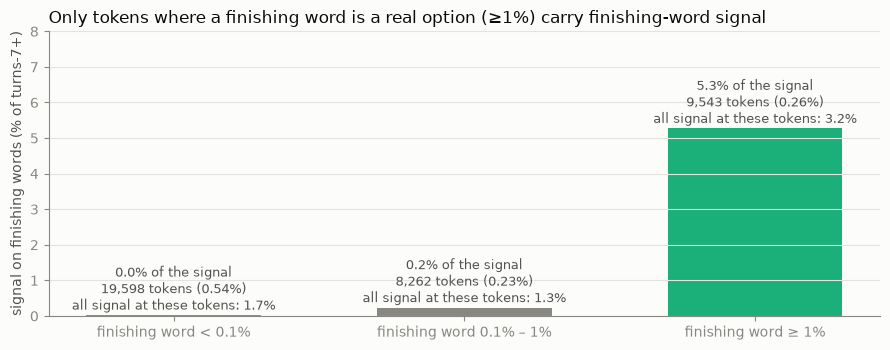

In [14]:
FINISHING = Path("runs/distill/finishing.npz")


def build_finishing():
    fin_max, fin_signal = np.zeros(len(signal)), np.zeros(len(signal))
    with SCORED.open() as f:
        for i, line in enumerate(f):
            e = json.loads(line)
            m = np.array(e["target_mask"], bool)
            rows = (turn[offsets[i]:offsets[i + 1]] >= 7) & (text_type[offsets[i]:offsets[i + 1]] == "thinking")
            ids = np.array(e["teacher_topk_ids"])[m][rows]
            log_q_t = np.array(e["teacher_topk_logprobs"])[m][rows]
            log_p_s = np.array(e["student_topk_logprobs"])[m][rows]
            p_t = np.exp(log_q_t - np.logaddexp.reduce(log_q_t, axis=1, keepdims=True))
            is_fin = is_finishing[ids]
            idx = np.flatnonzero(rows) + offsets[i]
            fin_max[idx] = np.where(is_fin, np.maximum(np.exp(log_q_t), np.exp(log_p_s)), 0).max(1)
            fin_signal[idx] = (p_t * (log_q_t - log_p_s) * is_fin).sum(1)
    np.savez(FINISHING, fin_max=fin_max, fin_signal=fin_signal)


if not FINISHING.exists():
    build_finishing()
fin = dict(np.load(FINISHING))

late_total = signal[late].sum()
buckets = [("< 0.1%", 1e-12, 0.001), ("0.1% – 1%", 0.001, 0.01), ("≥ 1%", 0.01, 2.0)]
fig, ax = plt.subplots(figsize=(9, 3.6))
for k, (name, a, b) in enumerate(buckets):
    s = late & (fin["fin_max"] >= a) & (fin["fin_max"] < b)
    on_words = fin["fin_signal"][s].sum() / late_total
    ax.bar(k, on_words * 100, color=AQUA if name == "≥ 1%" else MUTED, width=0.6)
    ax.annotate(f"{on_words:.1%} of the signal\n{s.sum():,} tokens ({s.sum() / late.sum():.2%})\n"
                f"all signal at these tokens: {signal[s].sum() / late_total:.1%}",
                (k, on_words * 100), xytext=(0, 4), textcoords="offset points", ha="center", color=INK_2, fontsize=9)
ax.set_xticks(range(len(buckets)), [f"finishing word {n}" for n, _, _ in buckets])
ax.set_ylim(0, 8)
ax.set_ylabel("signal on finishing words (% of turns-7+)")
ax.set_title("Only tokens where a finishing word is a real option (≥1%) carry finishing-word signal")
ax.grid(axis="x", visible=False)
fig.tight_layout()

The bar for ≥1% is larger than "all signal at these tokens" because at the same tokens the teacher also wants other words, like *also* or *check*, less; that part is negative and partly cancels in the token total.

## So

* most of the tokens carry no training signal (p0–p75) and we shouldn't supervise them
* the ones that carry some signal seem to have no clear direction upon inspection
* the target behavior is present in a very very small part of the dataset